In [57]:
import pandas as pd
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Wczytanie danych i inspekcja

In [58]:
# Wczytanie danych i czyszczenie
df = pd.read_csv("../output/features/all_features.csv")

#Inspekcja danych ile mamy NA
df.isna().sum()


gbifID                        0
decimalLongitude              0
decimalLatitude               0
wc2.1_30s_bio_1               0
wc2.1_30s_bio_10              0
wc2.1_30s_bio_11              0
wc2.1_30s_bio_12              0
wc2.1_30s_bio_13              0
wc2.1_30s_bio_14              0
wc2.1_30s_bio_15              0
wc2.1_30s_bio_16              0
wc2.1_30s_bio_17              0
wc2.1_30s_bio_18              0
wc2.1_30s_bio_19              0
wc2.1_30s_bio_2               0
wc2.1_30s_bio_3               0
wc2.1_30s_bio_4               0
wc2.1_30s_bio_5               0
wc2.1_30s_bio_6               0
wc2.1_30s_bio_7               0
wc2.1_30s_bio_8               0
wc2.1_30s_bio_9               0
Aspect                       19
Curvature                    26
DEM                          13
NDVI                         14
EVI                          14
SAVI                         14
NDWI                         14
BSI                          14
Slope                        19
Snow_Dur

## Bioclim 
BIOCLIM (Bioclimatic variables) to zestaw 19 globalnych zmiennych klimatycznych, wyprowadzonych z miesięcznych pomiarów temperatury i opadów. Zamiast prostych średnich, odzwierciedlają one uwarunkowania biologiczne i środowiskowe istotne dla życia organizmów.

        bio1="Annual Mean Temperature (°C)",
        bio2="Mean Diurnal Range",
        bio3="Isothermality",
        bio4="Temperature Seasonality",
        bio5="Max Temp Warmest Month",
        bio6="Min Temp Coldest Month",
        bio7="Temp Annual Range",
        bio8="Mean Temp Wettest Quarter",
        bio9="Mean Temp Driest Quarter",
        bio10="Mean Temp Warmest Quarter",
        bio11="Mean Temp Coldest Quarter",
        bio12="Annual Precipitation (mm)",
        bio13="Precipitation Wettest Month",
        bio14="Precipitation Driest Month",
        bio15="Precipitation Seasonality",
        bio16="Precipitation Wettest Quarter",
        bio17="Precipitation Driest Quarter",
        bio18="Precipitation Warmest Quarter",
        bio19="Precipitation Coldest Quarter"
        
Są one mocno z sobą skorelowane. Będziemy musieli wybrać do modelu odpowiednie.

            feature        VIF
0  wc2.1_30s_bio_19  57.695369
1  wc2.1_30s_bio_18  43.115827
2  wc2.1_30s_bio_15  23.433833
3   wc2.1_30s_bio_6  22.992355
4  wc2.1_30s_bio_10  18.967996
5   wc2.1_30s_bio_9  10.043593


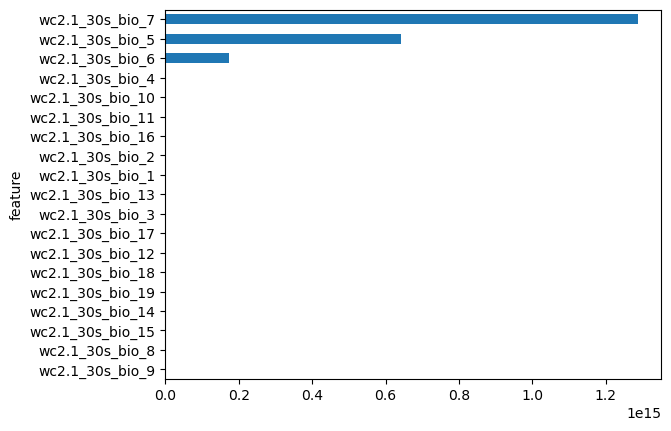

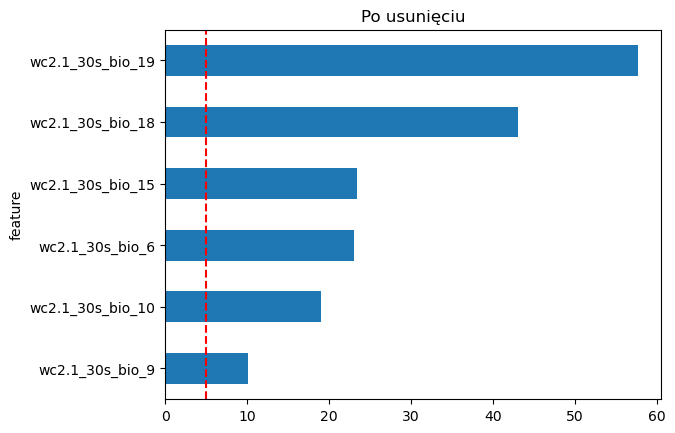

In [59]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor



def calculate_vif_wc(df):
    vif_data = pd.DataFrame()
    wybrane_kolumny = df.columns[df.columns.str.contains("wc", case=False)]
    features = df[wybrane_kolumny]
    vif_data["feature"] = features.columns
    vif_data["VIF"] = [variance_inflation_factor(features.values, i) for i in range(features.shape[1])]
    vif_df = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)
    return vif_df

# Sprawdzamy VIF

vif_df = calculate_vif_wc(df)
vif_df.sort_values(by="VIF").plot(
    kind="barh", x="feature", y="VIF", legend=False
)
#Wyrzucamy warstwy bioklimatyczne o njwiększym VIF ale takie które mają sens biologiczny
df_wc=df.drop(columns=["wc2.1_30s_bio_7", 
                       "wc2.1_30s_bio_1", 
                       "wc2.1_30s_bio_12", 
                       "wc2.1_30s_bio_4", 
                       "wc2.1_30s_bio_5", 
                       "wc2.1_30s_bio_16",
                       "wc2.1_30s_bio_11",
                       "wc2.1_30s_bio_14",
                       "wc2.1_30s_bio_13",
                       "wc2.1_30s_bio_3",
                       "wc2.1_30s_bio_17",
                       "wc2.1_30s_bio_8",
                       "wc2.1_30s_bio_2"])
vif_df = calculate_vif_wc(df_wc)
print(vif_df)
vif_df.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title = "Po usunięciu")
plt.axvline(x=5, color="r", linestyle="--")
df=df_wc

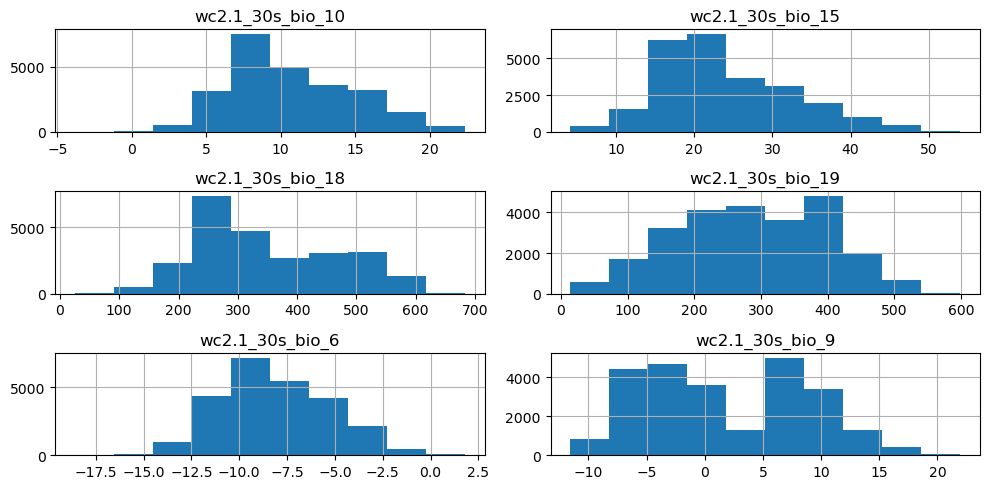

In [60]:
#Kolumny WC
wybrane_kolumny = df.columns[df.columns.str.contains("wc", case=False)]

#Histogramy dla WC
df[wybrane_kolumny].hist(bins=10, figsize=(10, 5))

#Wyświetlenie wykresu
plt.tight_layout()
plt.show()

## Snow Duration
Liczba dni w roku w których wystepuje pokrywa śnieżna. Dane z satelity Sentiel-1, pobrane z GEE.

<Axes: >

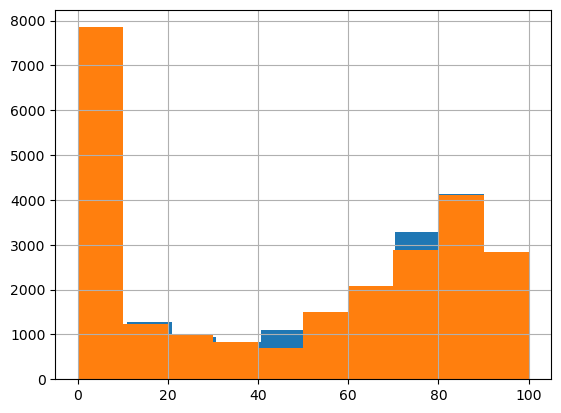

In [61]:
df["Snow_Duration_Pct"].hist()
df['Snow_Duration_Pct'] = df['Snow_Duration_Pct'].fillna(0)
#Uzupełnienie brakujących wartości w kolumnie "Snow_Duration_Pct" wartością 0. 
#"0" biologicznie oznacza brak opadów więc jest to legalne
df["Snow_Duration_Pct"].hist()

## Soil
Warstwy glebowe sa ważne bo te rośliny rosnać często na wapieniu lub granicie

In [62]:
df.isna().sum()
#Sporo warstw glebowych ma NA. Dzieje się tak jeśli występują na głównie na skale


gbifID                       0
decimalLongitude             0
decimalLatitude              0
wc2.1_30s_bio_10             0
wc2.1_30s_bio_15             0
wc2.1_30s_bio_18             0
wc2.1_30s_bio_19             0
wc2.1_30s_bio_6              0
wc2.1_30s_bio_9              0
Aspect                      19
Curvature                   26
DEM                         13
NDVI                        14
EVI                         14
SAVI                        14
NDWI                        14
BSI                         14
Slope                       19
Snow_Duration_Pct            0
Soil_Clay                  819
Soil_Organic_Carbon        818
Soil_pH                    819
Soil_Sand                  819
Topo_Solar_Radiation_MJ     19
TRI                         13
TWI                         19
dtype: int64

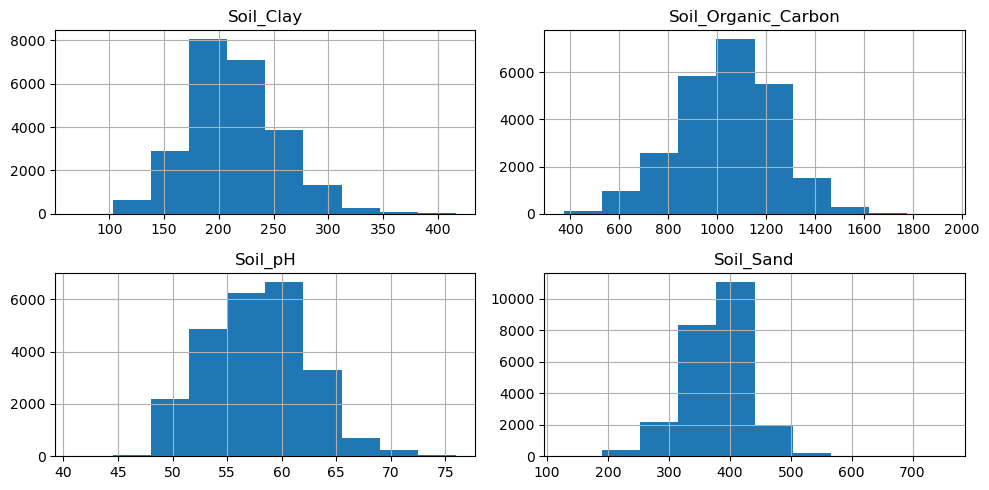

In [63]:
#Kolumny Soil
wybrane_kolumny = df.columns[df.columns.str.contains("soil", case=False)]

#Histogramy dla WC
df[wybrane_kolumny].hist(bins=10, figsize=(10, 5))

#Wyświetlenie wykresu
plt.tight_layout()
plt.show()

##

## Wskaźniki ekologiczne
1. NDVI (Normalized Difference Vegetation Index) wkaźnik gętosći zieleni. Od 1 do -1 Bujna roślinność 1 brak -1.
2. EVI (Enhanced Vegetation Index) ulepsozny NDVI porpzez dodanie światła niebieskiego
3. SAVI (Soil-Adjusted Vegetation Index) 
4. BSI (Bare Soil Index) wartość gołośći ziemi


VIF przed usunięciem:
   feature           VIF
0    SAVI  1.855178e+07
1    NDVI  1.855079e+07
2     BSI  2.818329e+00
3     EVI  1.056540e+00


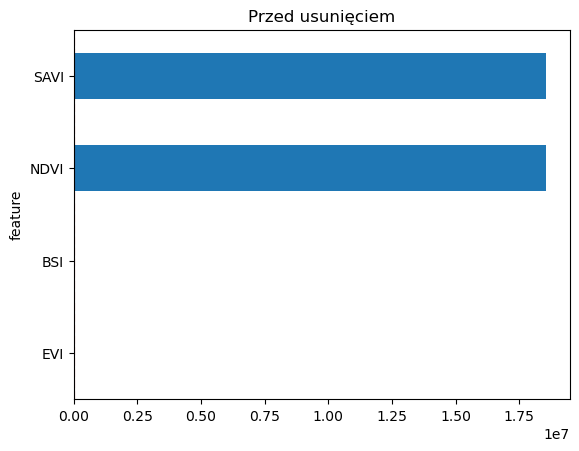

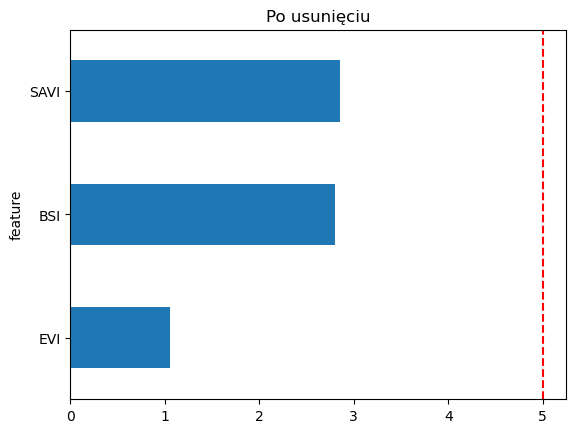

In [64]:
wskazniki_ekologiczne = ["NDVI", "EVI", "SAVI", "BSI"]


def calculate_vif_eco(data_frame, lista_kolumn):
    vif_data = pd.DataFrame()

    # Wycinamy tylko te, które istnieją w df, i usuwamy braki danych
    istniejace_kolumny = [col for col in lista_kolumn if col in data_frame.columns]
    X = data_frame[istniejace_kolumny].dropna()

    vif_data["feature"] = X.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X.values, i) for i in range(X.shape[1])
    ]
    return vif_data.sort_values(by="VIF", ascending=False).reset_index(
        drop=True
    )


df_eco = df
vif_przed = calculate_vif_eco(df, wskazniki_ekologiczne)
print("VIF przed usunięciem:\n", vif_przed)
vif_przed.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Przed usunięciem")
plt.axvline(x=5, color="r", linestyle="--")
plt.show()

#Usuwmay NVDI bo to defatko to samo 
df_cleaned = df_eco.drop(columns=["NDVI", "NDWI"])
vif_po = calculate_vif_eco(df_cleaned, wskazniki_ekologiczne)

#Wykres po
vif_po.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Po usunięciu")
plt.axvline(x=5, color="r", linestyle="--")
df=df_cleaned


In [65]:
#Wywalamy Nan
df = df.dropna()

#Usuwamy DEM aby uniezależnić model od wysokości, która jest silnie skorelowana z innymi warstwami
df = df.drop(columns="DEM")

# Konwersja kolumny na tekst, aby uniknąć błędów
df["gbifID"] = df["gbifID"].astype(str)

#Jeśli zawiera 'pseudo' -> 0, w przeciwnym wypadku -> 1
y = df["gbifID"].str.contains("pseudo", case=True).map({True: 0, False: 1})

#Definujemy X
columns_to_drop = ["gbifID", "decimalLongitude", "decimalLatitude"]
X = df.drop(columns=columns_to_drop)

                         wc2.1_30s_bio_10  wc2.1_30s_bio_15  wc2.1_30s_bio_18  \
wc2.1_30s_bio_10                 1.000000          0.471651          0.018169   
wc2.1_30s_bio_15                 0.471651          1.000000          0.198398   
wc2.1_30s_bio_18                 0.018169          0.198398          1.000000   
wc2.1_30s_bio_19                -0.409064         -0.714892         -0.020186   
wc2.1_30s_bio_6                  0.929700          0.313045         -0.041438   
wc2.1_30s_bio_9                  0.172647         -0.391663         -0.592576   
Aspect                          -0.008160         -0.015547         -0.019954   
Curvature                       -0.124721         -0.074983          0.023723   
EVI                              0.067733          0.042314          0.014209   
SAVI                             0.619605          0.417018          0.210127   
BSI                             -0.588855         -0.425207         -0.192686   
Slope                       

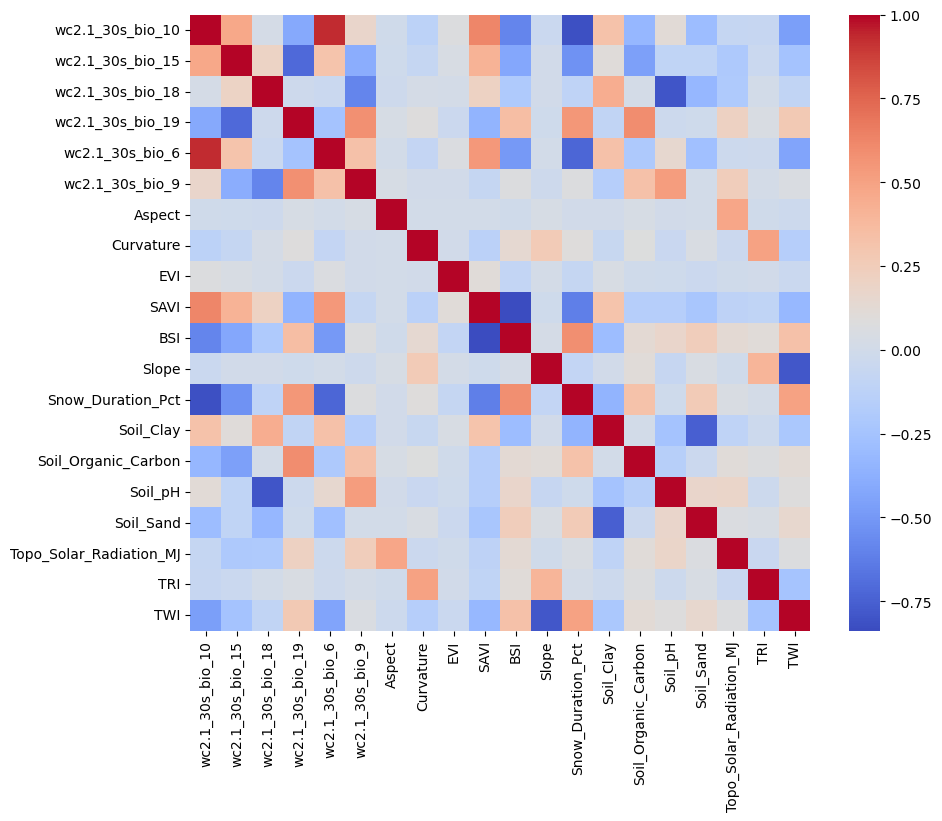

In [66]:
#Macierz korlacji dla liczbowych cech
d = X.select_dtypes(include=[np.number]).columns
macierz_korelacji = X[d].corr()

print(macierz_korelacji)

#Macierz korelacji heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(X[d].corr(numeric_only=True), cmap='coolwarm', fmt='.2f')
plt.show()

# PCA

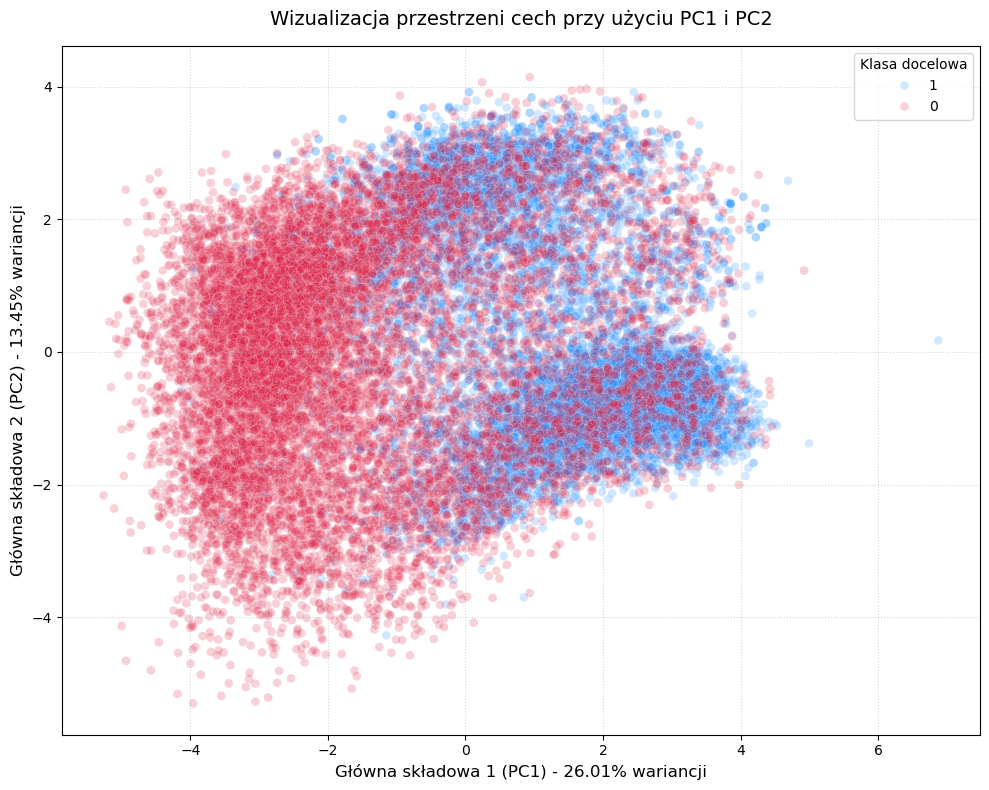

In [67]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Standaryzacja i dopasowanie PCA (9 składowych)
X_num = X.select_dtypes(include=["number"]).dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

pca_9 = PCA(n_components=9)
X_pca_9 = pca_9.fit_transform(X_scaled)

# Procent wariancji wyjaśnianej przez PC1 i PC2
var_pc1 = pca_9.explained_variance_ratio_[0] * 100
var_pc2 = pca_9.explained_variance_ratio_[1] * 100

# 2. Przygotowanie DataFrame do wykresu (łączenie z wektorem y)
# Upewniamy się, że indeksy X_num i y się zgadzają
y_num = y.loc[X_num.index]

df_wykres = pd.DataFrame(
    {"PC1": X_pca_9[:, 0], "PC2": X_pca_9[:, 1], "Klasa": y_num.astype(str)}
)

# 3. Tworzenie wykresu rozrzutu
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=df_wykres,
    x="PC1",
    y="PC2",
    hue="Klasa",
    palette={"0": "crimson", "1": "dodgerblue"},
    alpha=0.2,
    edgecolor="w",
    s=40,
)

# Estetyka i opisy
plt.title("Wizualizacja przestrzeni cech przy użyciu PC1 i PC2", fontsize=14, pad=15)
plt.xlabel(f"Główna składowa 1 (PC1) - {var_pc1:.2f}% wariancji", fontsize=12)
plt.ylabel(f"Główna składowa 2 (PC2) - {var_pc2:.2f}% wariancji", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(title="Klasa docelowa", loc="best")
plt.tight_layout()

# Wyświetlenie wykresu
plt.show()


# Random Forest

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=0)


In [70]:
#siatka parametrów do sprawdzenia
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, None], 
    'min_samples_split': [2, 5, 10],     
    'max_features': [None, 'sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

#konfiguracja grid
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(random_state=0), 
                           param_grid=param_grid, 
                           cv=5, 
                           n_jobs=5, 
                           verbose=1, 
                           scoring='accuracy')

# grid serach
grid_search.fit(X_train, y_train)

# najlepsze
print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"Najlepszy wynik (accuracy): {grid_search.best_score_}")

# zapis
best_tree = grid_search.best_estimator_

#Sprawdzenie na zbiorze testowym
y_pred = best_tree.predict(X_test)
print(metrics.classification_report(y_test, y_pred))

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Najlepsze parametry: {'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'min_samples_split': 2}
Najlepszy wynik (accuracy): 0.8264805237762716
              precision    recall  f1-score   support

           0       0.83      0.81      0.82      3571
           1       0.82      0.84      0.83      3674

    accuracy                           0.82      7245
   macro avg       0.83      0.82      0.82      7245
weighted avg       0.83      0.82      0.82      7245



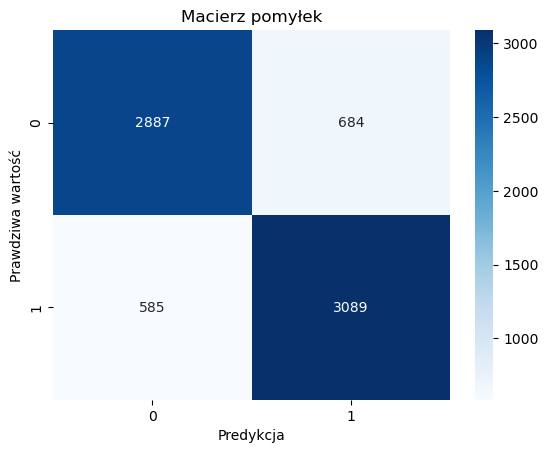

In [71]:
#Macierz pomyłek
cm = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predykcja')
plt.ylabel('Prawdziwa wartość')
plt.title('Macierz pomyłek')
plt.show()

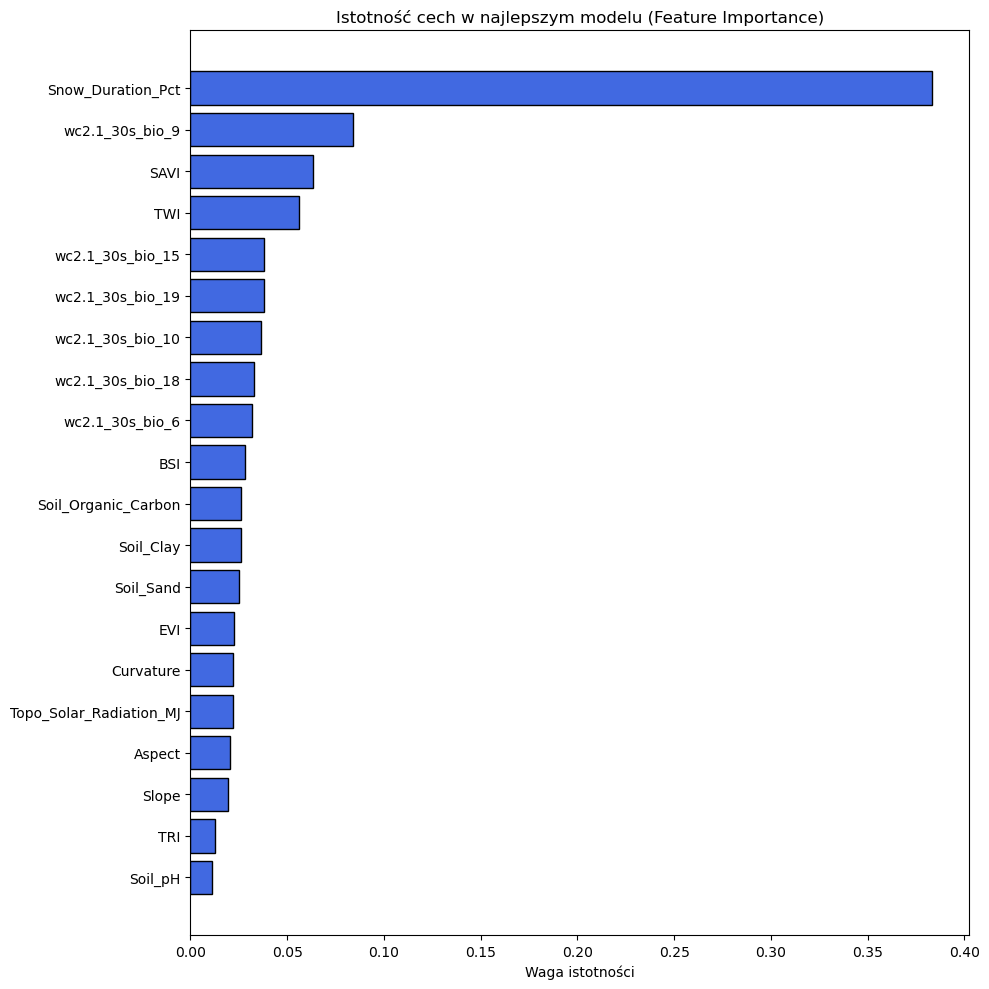

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pobranie istotności cech z najlepszego estymatora Grid Search
# Zastąp 'grid_search' nazwą swojej zmiennej z GridSearchCV
najlepszy_model = grid_search.best_estimator_
importances = najlepszy_model.feature_importances_

# Tworzenie DataFrame z wynikami
istotnosc_df = pd.DataFrame({
    'Cecha': X.columns,
    'Istotnosc': importances
}).sort_values(by='Istotnosc', ascending=True)

# Wykres poziomy
plt.figure(figsize=(10, 10))
plt.barh(istotnosc_df['Cecha'], istotnosc_df['Istotnosc'], color='royalblue', edgecolor='black')
plt.title('Istotność cech w najlepszym modelu (Feature Importance)')
plt.xlabel('Waga istotności')
plt.tight_layout()
plt.show()


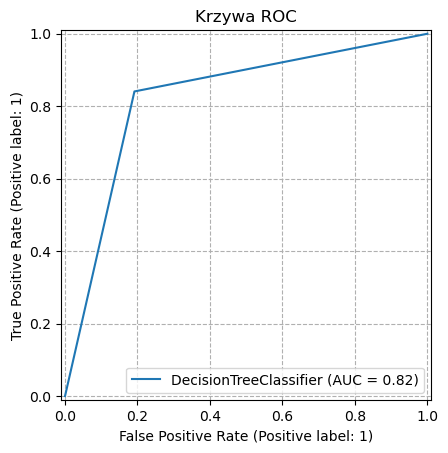

In [73]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(grid_search.best_estimator_, X_test, y_test)
plt.title("Krzywa ROC")
plt.grid(True, linestyle='--')
plt.show()


# RF

In [ ]:
from sklearn.ensemble import RandomForestClassifier
#siatka parametrów do sprawdzenia
param_grid = {
    "n_estimators": [200],  
    "criterion": ["gini"],
    "max_depth": [None],  # Głębokość pojedynczych drzew
    #"min_samples_split": [2, 5, 10],  # Min. liczba próbek do podziału węzła
    "max_features": ["sqrt"],  
    "class_weight": ["balanced"],
}

#konfiguracja grid
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=0, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    n_jobs=5,
    verbose=1,
    scoring="accuracy",
)

# grid serach
grid_search.fit(X_train, y_train)

# najlepsze
print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"Najlepszy wynik (accuracy): {grid_search.best_score_}")

# zapis
best_tree = grid_search.best_estimator_

#Sprawdzenie na zbiorze testowym
y_pred = best_tree.predict(X_test)
print(metrics.classification_report(y_test, y_pred))



Fitting 3 folds for each of 12 candidates, totalling 36 fits
Najlepsze parametry: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}
Najlepszy wynik (accuracy): 0.8719163354866727
              precision    recall  f1-score   support

           0       0.89      0.84      0.87      3571
           1       0.85      0.90      0.88      3674

    accuracy                           0.87      7245
   macro avg       0.87      0.87      0.87      7245
weighted avg       0.87      0.87      0.87      7245



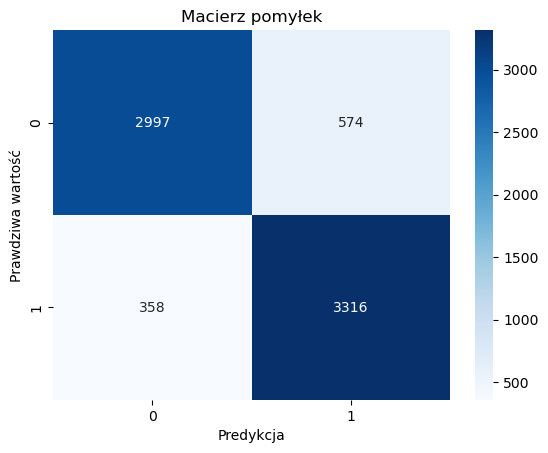

In [75]:
#Macierz pomyłek
cm = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predykcja')
plt.ylabel('Prawdziwa wartość')
plt.title('Macierz pomyłek')
plt.show()

# Grupowanie gatunków

--- ISTOTNOŚĆ (WSPÓŁCZYNNIKI ODWZOROWANIA) ZMIENNYCH NA OSIACH PCA ---
                           PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
wc2.1_30s_bio_10         0.213  0.420 -0.163 -0.119 -0.098  0.167  0.063   
wc2.1_30s_bio_15         0.313 -0.059 -0.051 -0.360  0.000  0.159  0.044   
wc2.1_30s_bio_18         0.377 -0.173  0.027  0.300  0.099 -0.053  0.097   
wc2.1_30s_bio_19        -0.256  0.240 -0.050  0.443 -0.015 -0.055  0.038   
wc2.1_30s_bio_6          0.149  0.452 -0.122 -0.024 -0.092  0.188  0.082   
wc2.1_30s_bio_9         -0.296  0.401 -0.112  0.068 -0.105  0.081 -0.012   
Aspect                  -0.037  0.072 -0.046 -0.058  0.697 -0.048  0.249   
Curvature                0.057  0.112  0.386  0.015 -0.114  0.004  0.580   
EVI                      0.021  0.027 -0.017 -0.002  0.002 -0.113  0.102   
SAVI                     0.239  0.163 -0.275 -0.018 -0.059 -0.492  0.044   
BSI                     -0.204 -0.149  0.272  0.021  0.066  0.551 -0.024   
Slope            

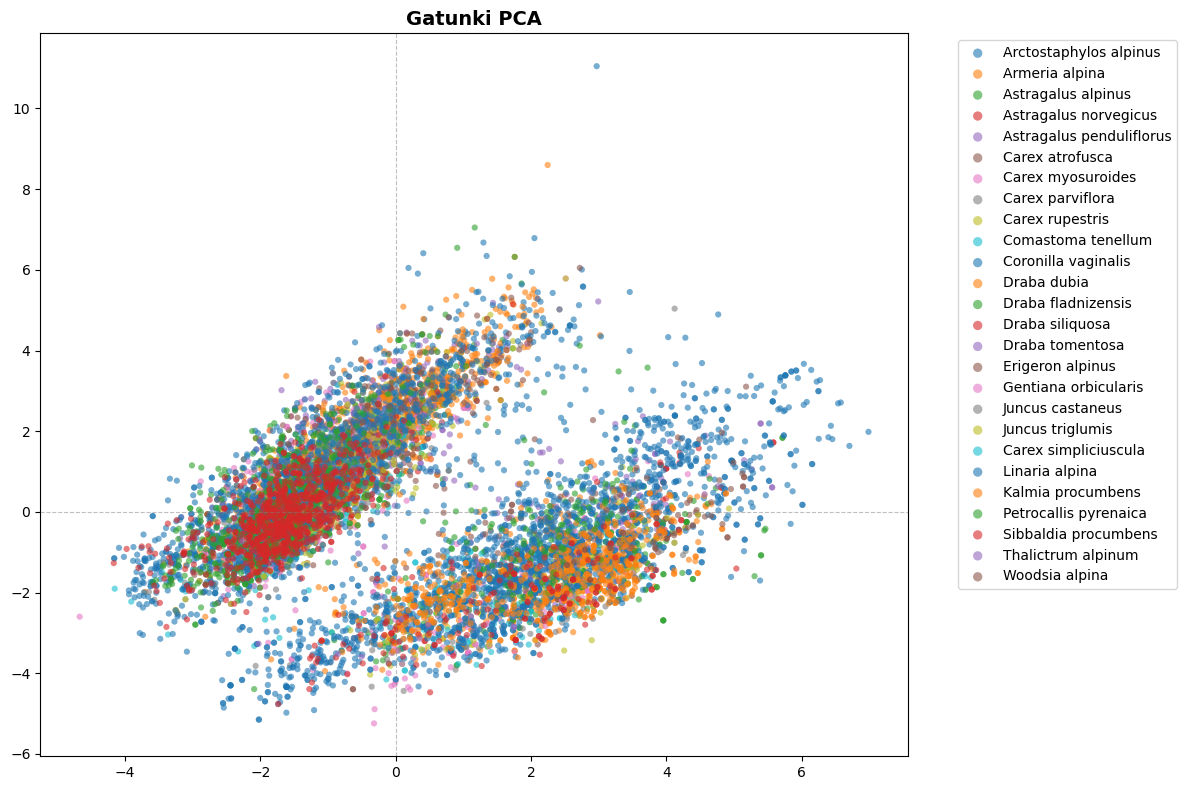

In [ ]:
#informacje o gatunkach
meta =pd.read_csv("../output/final_data/merged_all_species.csv")

# Konwersja kolumny gbifID na tekst w obu ramkach
df['gbifID'] = df['gbifID'].astype(str)
meta['gbifID'] = meta['gbifID'].astype(str)

#przygotowanie danych
df_full = pd.merge(df, meta[["gbifID", "species"]], on="gbifID", how="inner")

# Ignorujemy kolumny geograficzne i identyfikacyjne w analizie cech środowiskowych
banned_cols = ["gbifID", "species", "decimalLongitude", "decimalLatitude"]
features_cols = [col for col in df.columns if col not in banned_cols]

df_clean = df_full.dropna(subset=features_cols).reset_index(drop=True)
X = df_clean[features_cols]
y_species = df_clean["species"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#PCA z 9 składowymi, żeby mieć pełny obraz wpływu cech na przestrzeń cech
pca = PCA(n_components=9)
X_pca = pca.fit_transform(X_scaled)


# Obliczamy ładunki (loadings) - wpływ każdej zmiennej na PC1 i PC2
loadings = pd.DataFrame(
    pca.components_.T, columns=[f"PC{i+1}" for i in range(9)], index=features_cols
)

print("--- ISTOTNOŚĆ (WSPÓŁCZYNNIKI ODWZOROWANIA) ZMIENNYCH NA OSIACH PCA ---")
print(loadings.round(3))

#wykres PCA dla gatunków
plt.figure(figsize=(12, 8))

# Rysujemy punkty dla każdego gatunku osobno na jednym wykresie (plt)
for species_name in y_species.unique():
    mask = y_species == species_name
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none",
    )

plt.title(
    "Gatunki PCA",
    fontsize=14,
    fontweight="bold",
)

# Przemieszczamy legendę poza wykres, żeby nie zasłaniała punktów przy wielu gatunkach
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", markerscale=1.5)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.show()

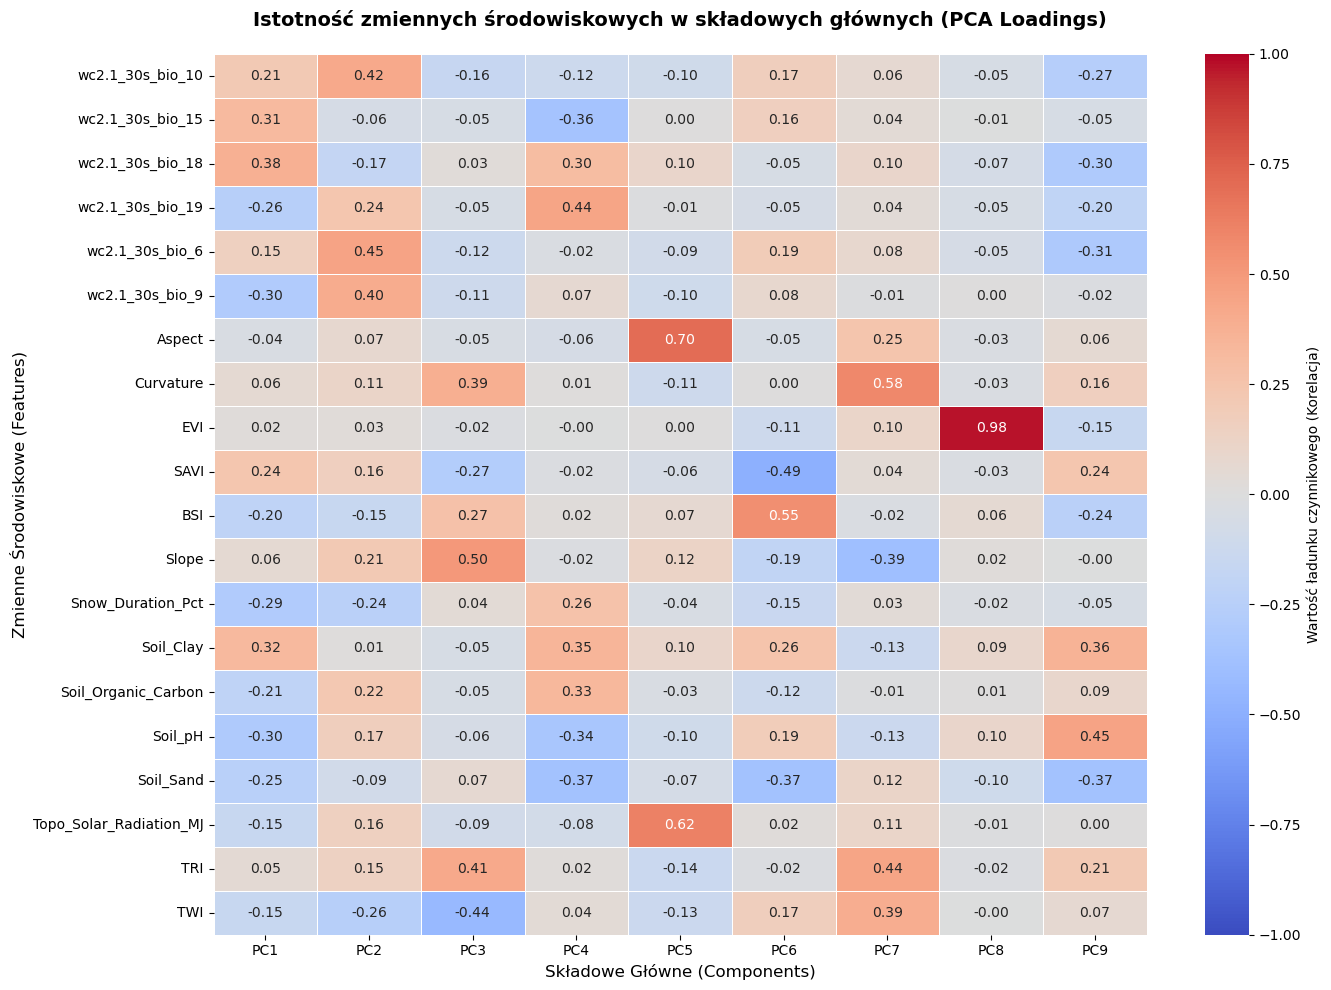

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================================
# HEATMAPA ŁADUNKÓW CZYNNIKOWYCH (LOADINGS)
# =====================================================================
plt.figure(figsize=(14, 10))

# Używamy coolwarm - idealna paleta dla wartości od -1 do 1
# vmin i vmax centrują nam kolor biały idealnie na wartości 0
sns.heatmap(
    loadings,
    annot=True,  # Wyświetla wartości liczbowe w kwadratach
    fmt=".2f",  # Zaokrąglenie do 2 miejsc po przecinku
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,  # Delikatne linie siatki separujące komórki
    cbar_kws={"label": "Wartość ładunku czynnikowego (Korelacja)"},
)

plt.title(
    "Istotność zmiennych środowiskowych w składowych głównych (PCA Loadings)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Składowe Główne (Components)", fontsize=12)
plt.ylabel("Zmienne Środowiskowe (Features)", fontsize=12)

# Rotacja etykiet, żeby tekst na siebie nie nachodził
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


--- URUCHAMIANIE KLASTROWANIA K-MEANS (K=2) ---


Cluster
1    8044
0    4121
Name: count, dtype: int64


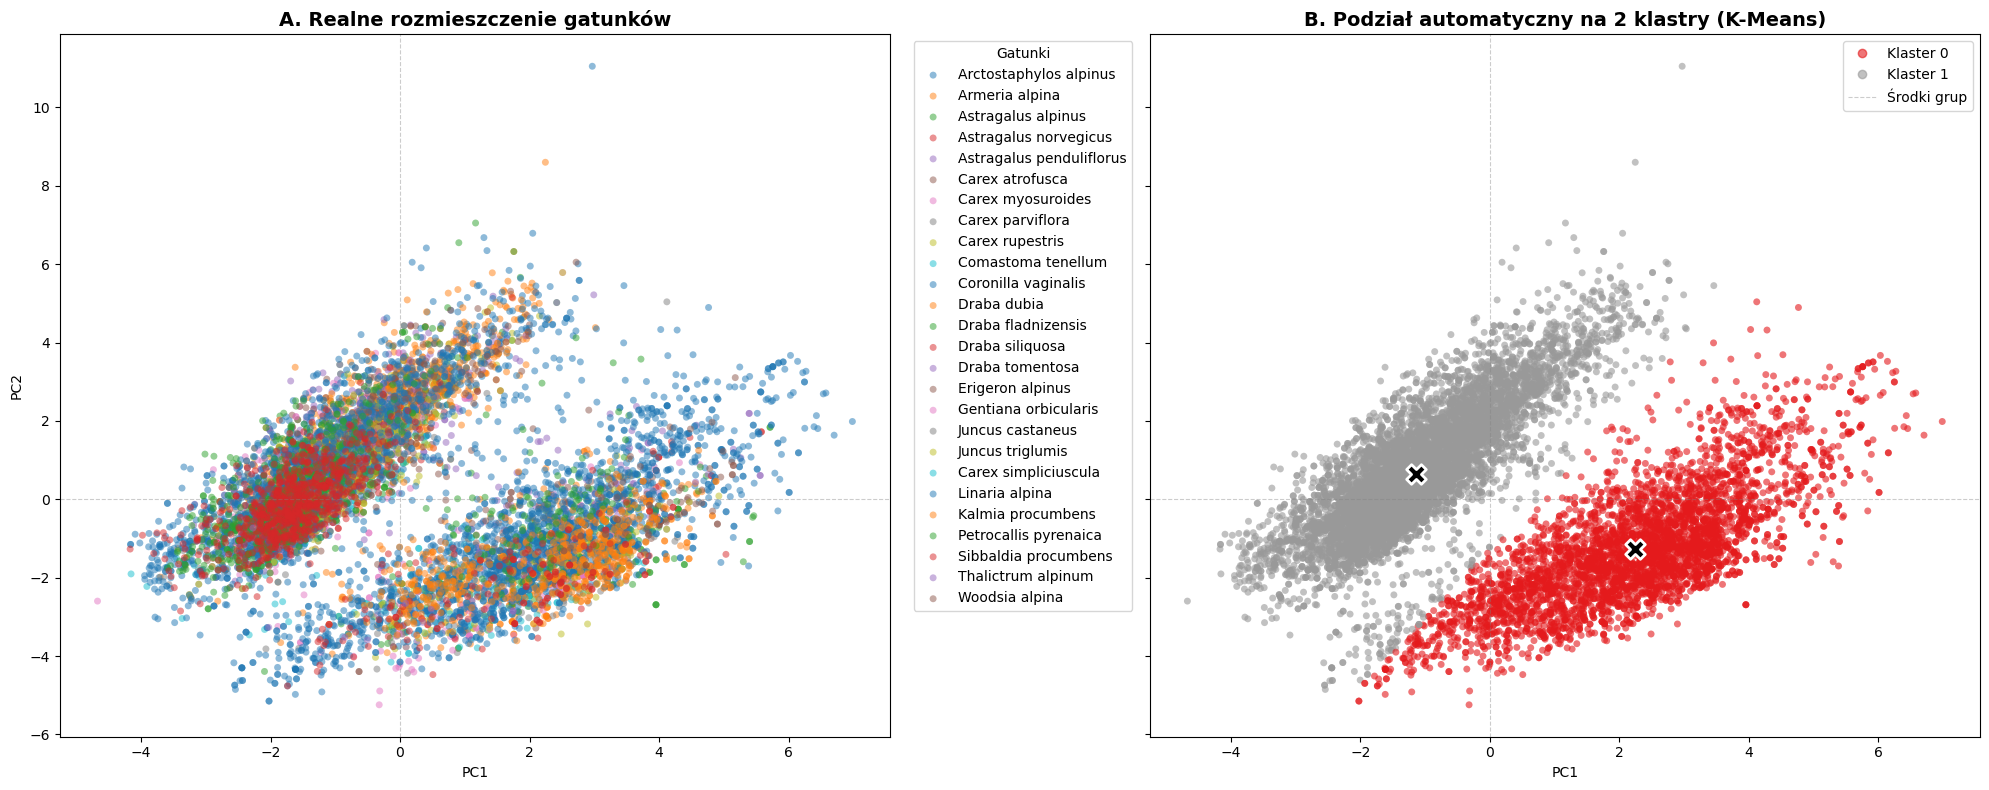


--- SKŁAD GATUNKOWY POSZCZEGÓLNYCH KLASTRÓW (%) ---
Cluster                       0     1
species                              
Arctostaphylos alpinus     95.7   4.3
Armeria alpina             27.2  72.8
Astragalus alpinus         47.8  52.2
Astragalus norvegicus     100.0   0.0
Astragalus penduliflorus   27.2  72.8
Carex atrofusca           100.0   0.0
Carex myosuroides           9.1  90.9
Carex parviflora           13.9  86.1
Carex rupestris             6.5  93.5
Carex simpliciuscula      100.0   0.0
Comastoma tenellum         20.7  79.3
Coronilla vaginalis        43.5  56.5
Draba dubia                 4.6  95.4
Draba fladnizensis         12.8  87.2
Draba siliquosa            13.0  87.0
Draba tomentosa            66.7  33.3
Erigeron alpinus           27.8  72.2
Gentiana orbicularis       30.4  69.6
Juncus castaneus          100.0   0.0
Juncus triglumis           23.2  76.8
Kalmia procumbens          98.1   1.9
Linaria alpina             47.7  52.3
Petrocallis pyrenaica      12.9  87

In [79]:
import seaborn as sns
from sklearn.cluster import KMeans

# =====================================================================
# 4. KLASTROWANIE K-MEANS (NA DWIE GRUPY)
# =====================================================================
print("\n--- URUCHAMIANIE KLASTROWANIA K-MEANS (K=2) ---")

# Definiujemy algorytm dla 2 klastrów
# random_state gwarantuje, że przy każdym uruchomieniu dostaniesz ten sam wynik
kmeans = KMeans(n_clusters=2, init="k-means++", random_state=42)

# Klastrujemy na podstawie współrzędnych PCA (pierwszych dwóch składowych, na których rysujesz)
# Można też klastrować na pełnym X_scaled - w ekologii obie szkoły są poprawne,
# ale klastrowanie na X_pca[col 0, col 1] idealnie odzwierciedla to, co widzisz na wykresie.
df_clean["Cluster"] = kmeans.fit_predict(X_pca[:, :2])

# Podgląd liczebności w grupach
print(df_clean["Cluster"].value_counts())


# =====================================================================
# 5. WIZUALIZACJA PORÓWNAWCZA: GATUNKI VS KLASTRY
# =====================================================================
# Tworzymy panel z dwoma wykresami obok siebie (1 wiersz, 2 kolumny)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), sharex=True, sharey=True)

# Lewy wykres: Gatunki (odtworzenie Twojego oryginalnego wykresu)
for species_name in y_species.unique():
    mask = y_species == species_name
    ax1.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species_name,
        alpha=0.5,
        s=25,
        edgecolors="none",
    )

ax1.set_title("A. Realne rozmieszczenie gatunków", fontsize=14, fontweight="bold")
ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax1.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Gatunki")
ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
ax1.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)

# Prawy wykres: Wynik klastrowania na 2 grupy
scatter_clusters = ax2.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df_clean["Cluster"],
    cmap="Set1",  # Wyraziste, kontrastowe kolory dla dwóch grup
    alpha=0.6,
    s=25,
    edgecolors="none",
)

# Dodajemy centra klastrów (reprezentatywne punkty środkowe obu grup)
centroids = kmeans.cluster_centers_
ax2.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    linewidths=2,
    color="black",
    edgecolors="white",
    label="Centra klastrów",
)

ax2.set_title(
    "B. Podział automatyczny na 2 klastry (K-Means)",
    fontsize=14,
    fontweight="bold",
)
ax2.set_xlabel("PC1")
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
ax2.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)

# Tworzenie czytelnej legendy dla klastrów
labels = [f"Klaster {i}" for i in range(2)]
legend_elements = scatter_clusters.legend_elements()[0]
ax2.legend(
    legend_elements + [ax2.lines[-1]],
    labels + ["Środki grup"],
    loc="upper right",
)

plt.tight_layout()
plt.show()

# =====================================================================
# 6. ANALIZA EKOLOGICZNA: KTÓRE GATUNKI TWORZĄ KLASTRY?
# =====================================================================
print("\n--- SKŁAD GATUNKOWY POSZCZEGÓLNYCH KLASTRÓW (%) ---")
sklad_klastrow = (
    pd.crosstab(df_clean["species"], df_clean["Cluster"], normalize="index")
    * 100
)
print(sklad_klastrow.round(1))

# UMAP

--- URUCHAMIANIE MANIPULACJI PRZESTRZENI UMAP ---


/home/janek/miniconda3/envs/python/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


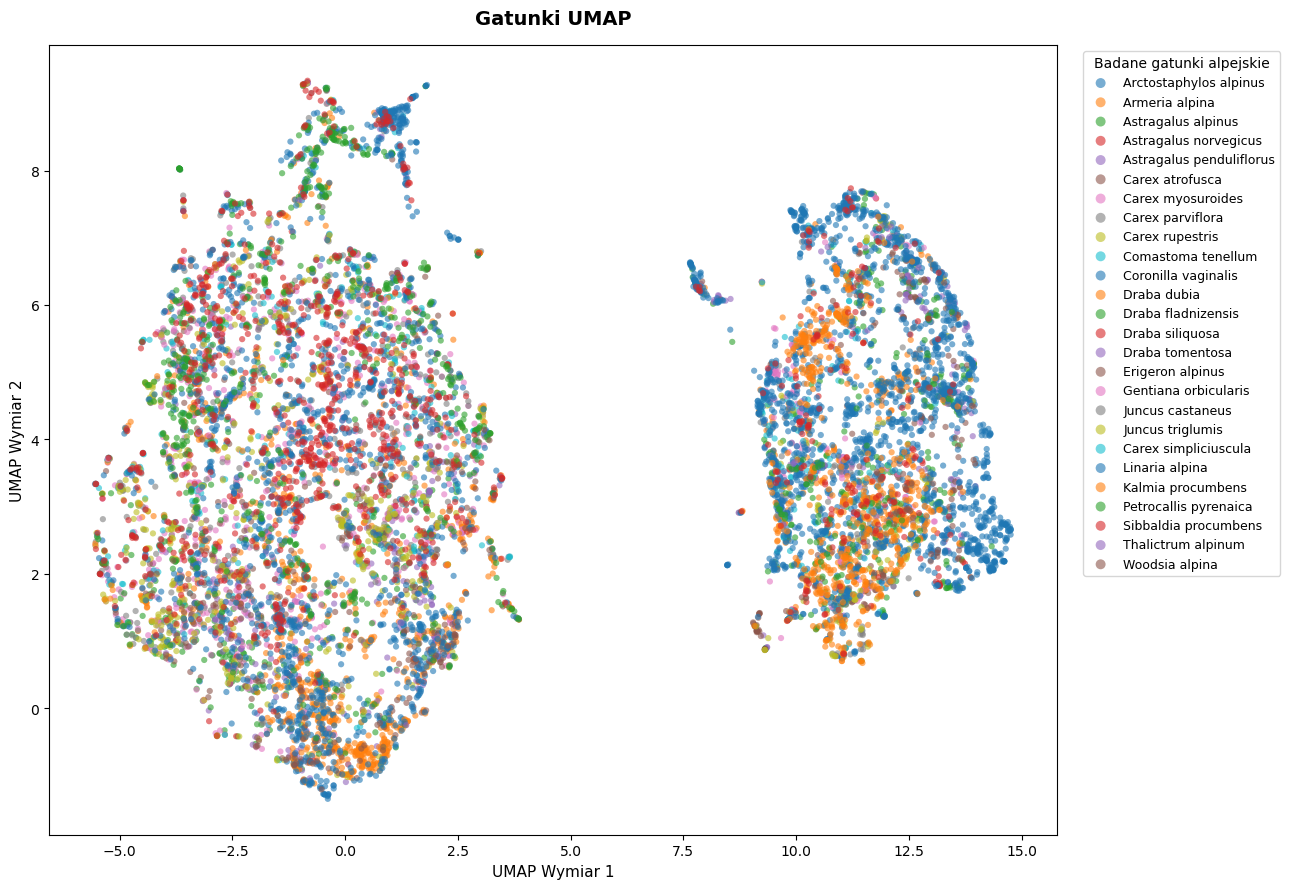

In [80]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
import umap

# =====================================================================
# 1. PRZYGOTOWANIE DANYCH I STANDARYZACJA
# =====================================================================
# Filtrujemy tylko kolumny numeryczne (cechy środowiskowe)
banned_cols = ["gbifID", "species", "decimalLongitude", "decimalLatitude", "Cluster", "kmeans_cluster"]
features_cols = [col for col in df_clean.columns if col not in banned_cols]

X_numeric = df_clean[features_cols]
y_species = df_clean["species"]

# UMAP, podobnie jak PCA, bezwzględnie wymaga ujednolicenia skal zmiennych
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

# =====================================================================
# 2. REDUKCJA WYMIARÓW ZA POMOCĄ UMAP
# =====================================================================
print("--- URUCHAMIANIE MANIPULACJI PRZESTRZENI UMAP ---")

# Kluczowe parametry:
# - n_neighbors: kontroluje balans między strukturą lokalną a globalną (wyższa wartość = bardziej globalne spojrzenie)
# - min_dist: określa, jak ciasno punkty mogą się grupować (niższa wartość = ściślejsze, odseparowane klastry)
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

# =====================================================================
# 3. WIZUALIZACJA: WYKRES UMAP Z PODZIAŁEM NA GATUNKI
# =====================================================================
plt.figure(figsize=(13, 9))

# Mapujemy każdy unikalny gatunek na punkty w nowej przestrzeni UMAP
for species_name in y_species.unique():
    mask = y_species == species_name
    plt.scatter(
        X_umap[mask, 0],
        X_umap[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none"
    )

# Opisy i formatowanie osi
plt.title(
    "Gatunki UMAP",
    fontsize=14,
    fontweight="bold",
    pad=15
)
plt.xlabel("UMAP Wymiar 1", fontsize=11)
plt.ylabel("UMAP Wymiar 2", fontsize=11)

# Legenda wyciągnięta na bok z zachowaniem skali punktów
plt.legend(
    title="Badane gatunki alpejskie",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    markerscale=1.6,
    fontsize=9
)

plt.tight_layout()
plt.show()

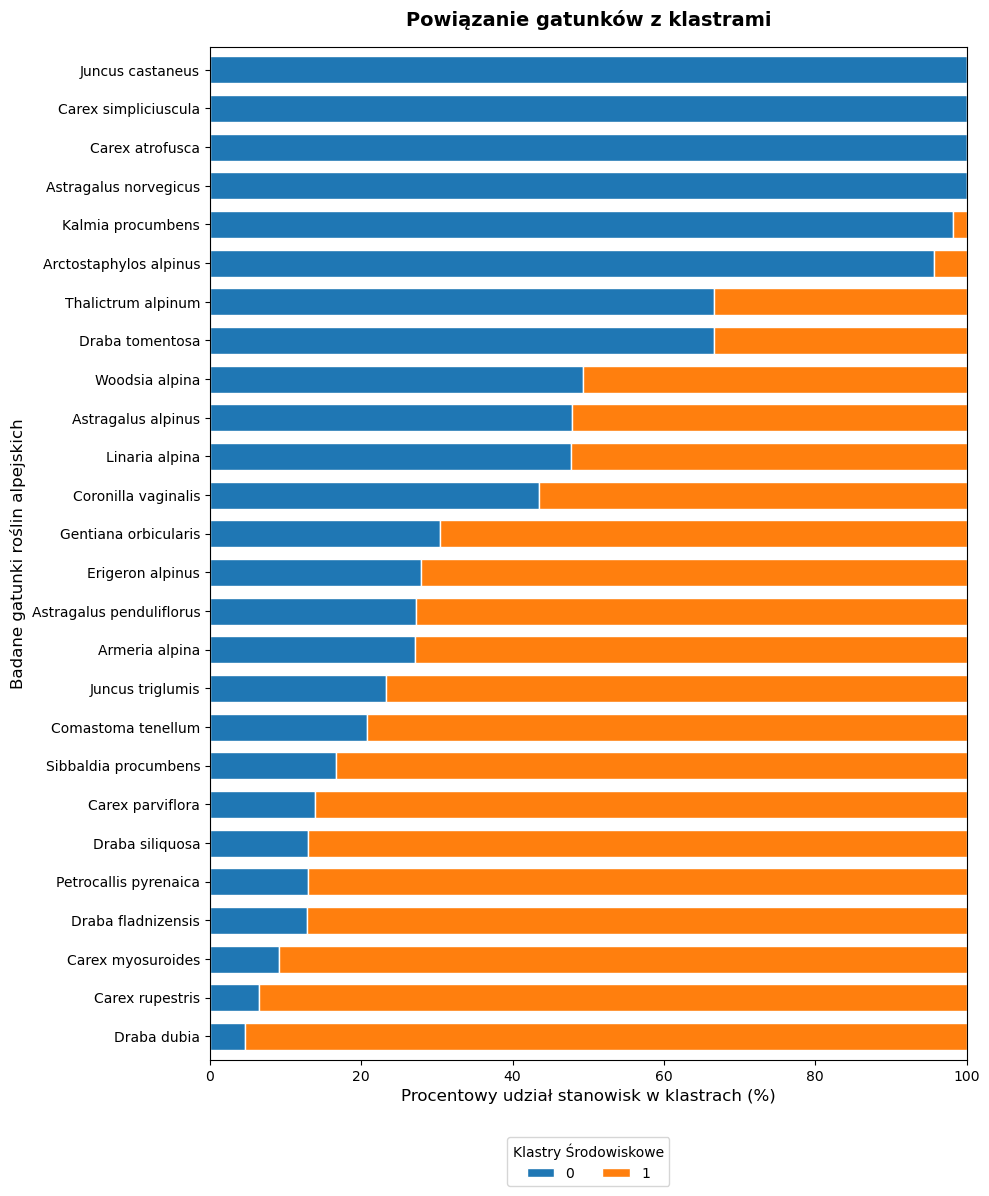

In [81]:
#Obliczamy rozkład klastrów wewnątrz każdego gatunku
sklad_counts = pd.crosstab(df_clean["species"], df_clean["Cluster"])

# Normalizacja
sklad_gatunkowy_procent = sklad_counts.div(sklad_counts.sum(axis=1), axis=0) * 100

# Sortujemy 
sklad_gatunkowy_procent = sklad_gatunkowy_procent.sort_values(by=0, ascending=True)

# WYkres poziomy
fig, ax = plt.subplots(figsize=(10, 12))

sklad_gatunkowy_procent.plot(
    kind="barh",  
    stacked=True,
    ax=ax,
    edgecolor="white",
    width=0.7
)

# Stylizacja wykresu - zamieniamy miejscami etykiety X i Y
plt.title(
    "Powiązanie gatunków z klastrami",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Badane gatunki roślin alpejskich", fontsize=12)
plt.xlabel("Procentowy udział stanowisk w klastrach (%)", fontsize=12)

# Nazwy gatunków są teraz poziomo, więc rotation=0 i wyrównanie do prawej
plt.yticks(fontsize=10)
plt.xticks(fontsize=10)

# Konfiguracja legendy (przeniesiona na dół pod wykres, żeby poziomy wykres miał więcej miejsca)
plt.legend(
    title="Klastry Środowiskowe",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2
)

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

--- TRENOWANIE MODELU RANDOM FOREST ---

--- RAPORT KLASYFIKACJI ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       824
           1       1.00      1.00      1.00      1609

    accuracy                           1.00      2433
   macro avg       1.00      1.00      1.00      2433
weighted avg       1.00      1.00      1.00      2433



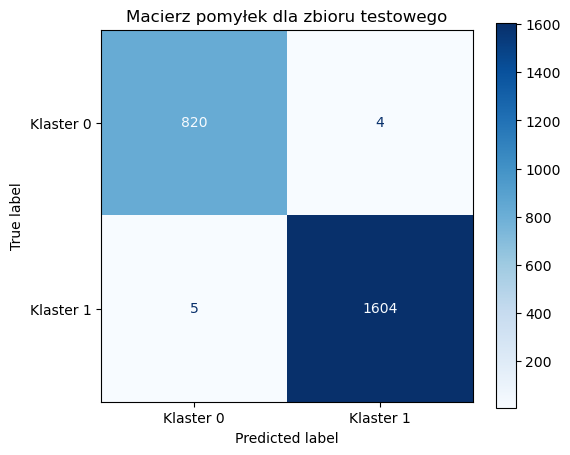

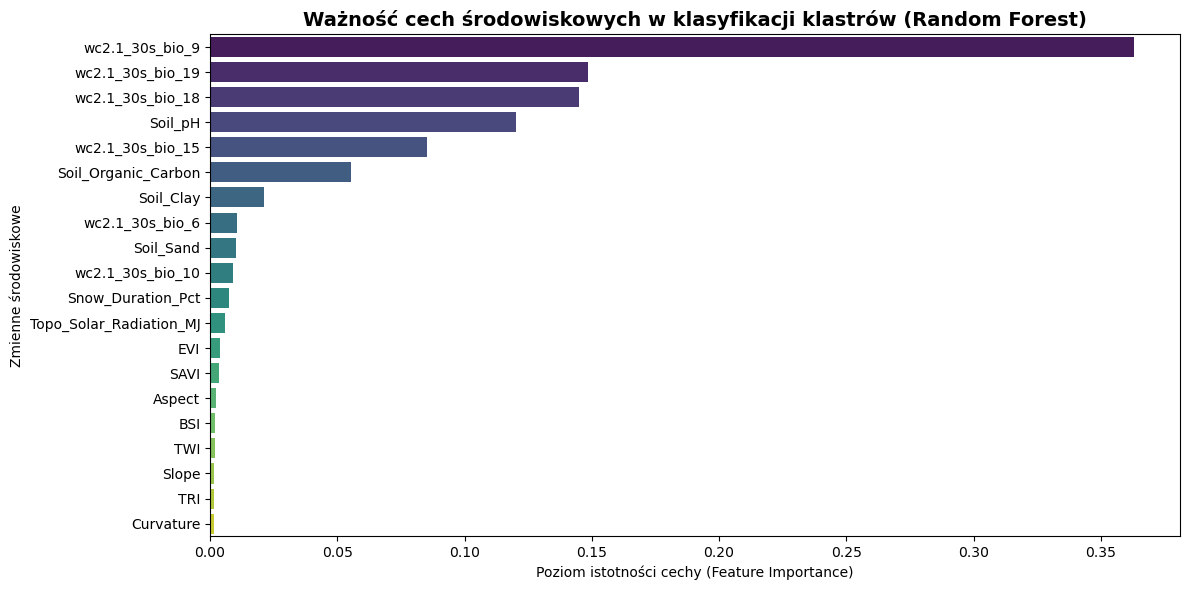

In [82]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# =====================================================================
# 1. PRZYGOTOWANIE DANYCH DO RANDOM FOREST
# =====================================================================
# Upewniamy się, że mamy czystą ramkę z cechami i etykietą klastra
# Używamy cech oryginalnych (X), a nie PCA, żeby móc zinterpretować, które realne zmienne (np. DEM, pH) są ważne!
X_rf = df_clean[features_cols]
y_rf = df_clean["Cluster"]  # Nasze klasy: 0 i 1

# Podział na zbiór treningowy i testowy (80% trening, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_rf, y_rf, test_size=0.2, random_state=42, stratify=y_rf
)

# =====================================================================
# 2. TRENOWANIE MODELU RANDOM FOREST
# =====================================================================
print("--- TRENOWANIE MODELU RANDOM FOREST ---")
# n_estimators=100 (liczba drzew w lesie), max_depth pozwala kontrolować przeuczenie
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predykcja na zbiorze testowym
y_pred = rf_model.predict(X_test)

# =====================================================================
# 3. OCENA JAKOŚCI MODELU (RAPORT I MACIERZ POMYŁEK)
# =====================================================================
print("\n--- RAPORT KLASYFIKACJI ---")
print(classification_report(y_test, y_pred))

# Wyświetlenie macierzy pomyłek (Confusion Matrix)
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Klaster 0", "Klaster 1"])
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Macierz pomyłek dla zbioru testowego")
plt.grid(False)
plt.show()

# =====================================================================
# 4. ISTOTNOŚĆ ZMIENNYCH (FEATURE IMPORTANCE)
# =====================================================================
# Wyciągamy ważność cech z modelu
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Tworzymy DataFrame dla łatwiejszego rysowania
df_importance = pd.DataFrame({
    "Cecha Środowiskowa": [features_cols[i] for i in indices],
    "Ważność (MDI)": [importances[i] for i in indices]
})

# Wykres słupkowy ważności cech
plt.figure(figsize=(12, 6))
sns.barplot(
    x="Ważność (MDI)", 
    y="Cecha Środowiskowa", 
    data=df_importance, 
    palette="viridis",
    hue="Cecha Środowiskowa",
    legend=False
)

plt.title("Ważność cech środowiskowych w klasyfikacji klastrów (Random Forest)", fontsize=14, fontweight="bold")
plt.xlabel("Poziom istotności cechy (Feature Importance)")
plt.ylabel("Zmienne środowiskowe")
plt.tight_layout()
plt.show()

In [83]:
df_importance

,Cecha Środowiskowa,Ważność (MDI)
0,wc2.1_30s_bio_9,0.362953
1,wc2.1_30s_bio_19,0.148579
2,wc2.1_30s_bio_18,0.144794
3,Soil_pH,0.120044
4,wc2.1_30s_bio_15,0.085376
5,Soil_Organic_Carbon,0.055383
6,Soil_Clay,0.021376
7,wc2.1_30s_bio_6,0.010739
8,Soil_Sand,0.010037
9,wc2.1_30s_bio_10,0.009218


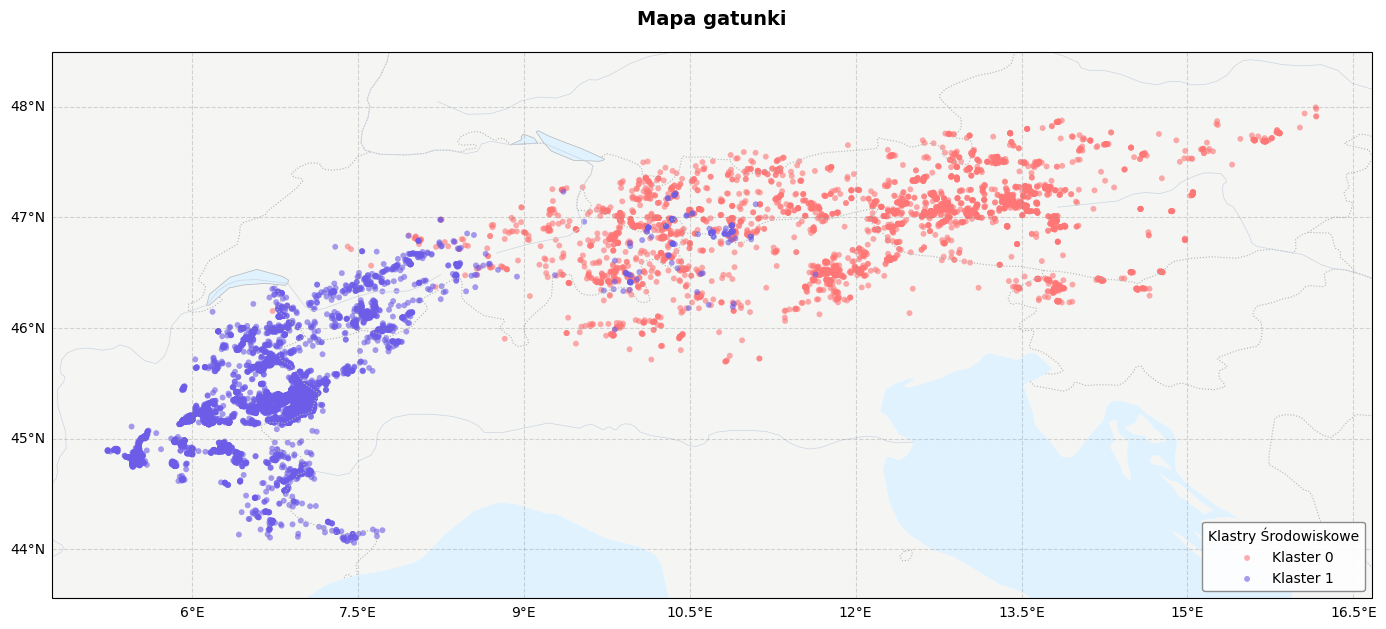

In [84]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt


# 2. Inicjalizacja wykresu z odpowiednią projekcją geograficzną (PlateCarree dla czystych koordynatów GPS)
fig, ax = plt.subplots(figsize=(14, 10), subplot_kw={'projection': ccrs.PlateCarree()})


# Wybieramy poziom szczegółowości (10m = bardzo dokładna, 50m = średnia/szybka, 110m = globalna)
scale = '50m'

# Dodajemy naturalne tło lądów i oceanów
ax.add_feature(cfeature.LAND.with_scale(scale), facecolor='#f5f5f3')
ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor='#e0f2fe')

# Dodajemy granice polityczne państw (subtelne, szare linie, żeby nie zasłaniały punktów)
ax.add_feature(cfeature.BORDERS.with_scale(scale), edgecolor='#b5b5b5', linewidth=0.8, linestyle=':')

# Opcjonalnie: Dodanie głównych rzek i jezior dla lepszej orientacji w Alpach
ax.add_feature(cfeature.LAKES.with_scale(scale), facecolor='#e0f2fe', edgecolor='#b5b5b5', linewidth=0.5)
ax.add_feature(cfeature.RIVERS.with_scale(scale), edgecolor='#cbd5e1', linewidth=0.5)
# =====================================================================

kolory_klastrow = {0: "#ff7675", 1: "#6c5ce7"}

# 3. Rysujemy punkty dla każdego klastra
for cluster_id, kolor in kolory_klastrow.items():
    mask = df_clean["Cluster"] == cluster_id
    ax.scatter(
        df_clean.loc[mask, "decimalLongitude"],
        df_clean.loc[mask, "decimalLatitude"],
        c=kolor,
        label=f"Klaster {cluster_id}",
        alpha=0.6,
        s=18,
        edgecolors="none",
        transform=ccrs.PlateCarree() # Informujemy Cartopy, że dane to surowe stopnie Long/Lat
    )

# 4. Automatyczne kadrowanie mapy z lekkim marginesem wokół Twoich punktów alpejskich
pad = 0.5
ax.set_extent([
    df_clean["decimalLongitude"].min() - pad,
    df_clean["decimalLongitude"].max() + pad,
    df_clean["decimalLatitude"].min() - pad,
    df_clean["decimalLatitude"].max() + pad
], crs=ccrs.PlateCarree())

# 5. Dodanie profesjonalnej siatki kartograficznej z etykietami współrzędnych
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.3)
gl.top_labels = False   # Wyłączamy górne podpisy, żeby nie dublować tytułu
gl.right_labels = False # Wyłączamy prawe podpisy dla czystości kadru

# Stylizacja
plt.title(
    "Mapa gatunki",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.legend(
    title="Klastry Środowiskowe",
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="gray",
    framealpha=0.9
)

plt.tight_layout()
plt.show()

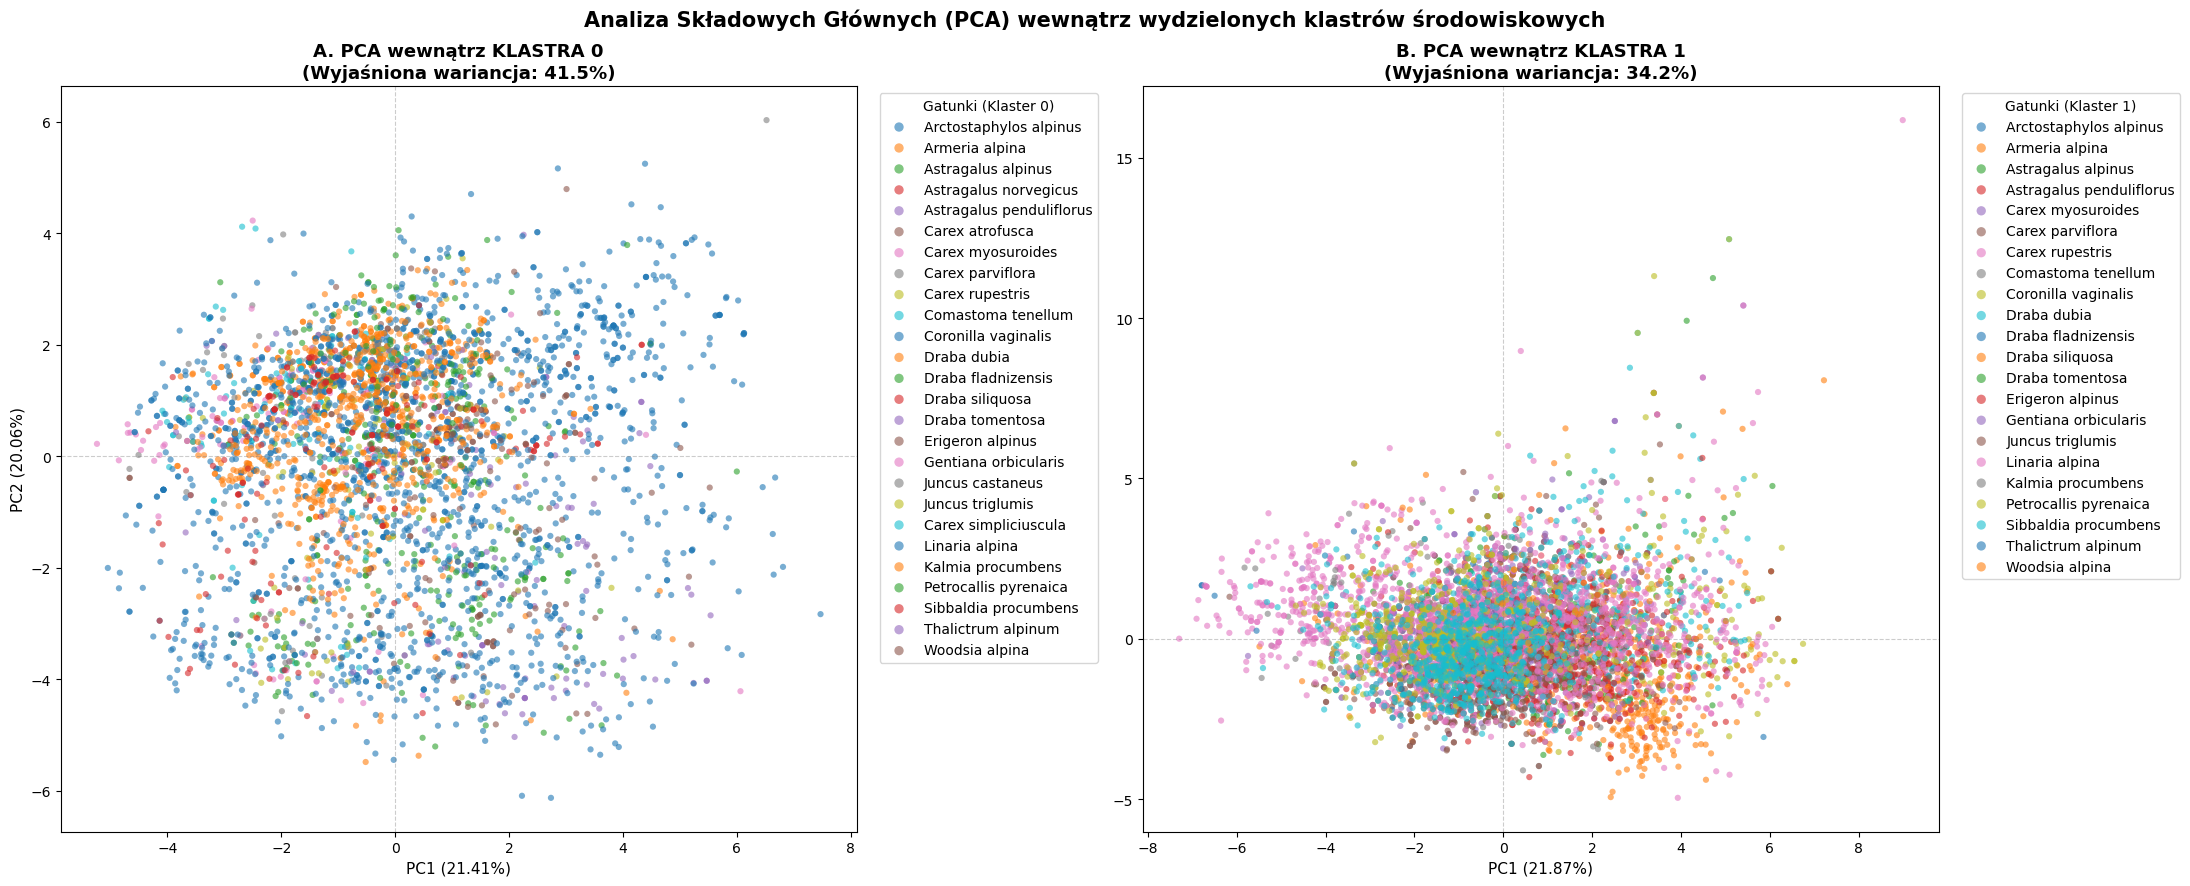

--- TOP 3 ZMIENNE BUDUJĄCE PC1 WEWNĄTRZ KLASTRA 0 ---
wc2.1_30s_bio_10     0.443895
wc2.1_30s_bio_6      0.403582
wc2.1_30s_bio_9      0.388493
wc2.1_30s_bio_15     0.381826
Snow_Duration_Pct    0.361340
Name: PC1, dtype: float64

--- TOP 3 ZMIENNE BUDUJĄCE PC1 WEWNĄTRZ KLASTRA 1 ---
wc2.1_30s_bio_10     0.427361
wc2.1_30s_bio_6      0.417759
wc2.1_30s_bio_9      0.356734
Snow_Duration_Pct    0.319193
SAVI                 0.281850
Name: PC1, dtype: float64


In [85]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Upewniamy się, że rysujemy na bazie cech środowiskowych (bez ID i klastrów)
banned_cols = ["gbifID", "species", "decimalLongitude", "decimalLatitude", "Cluster", "kmeans_cluster"]
features_cols = [col for col in df_clean.columns if col not in banned_cols]

# =====================================================================
# 1. PCA WEWNĄTRZ KLASTRA 0 (np. Krzewinki / Lewa strona)
# =====================================================================
df_c0 = df_clean[df_clean["Cluster"] == 0].reset_index(drop=True)

X_c0 = df_c0[features_cols]
y_species_c0 = df_c0["species"]

# Standaryzacja i dopasowanie PCA dedykowanego dla Klastra 0
scaler_c0 = StandardScaler()
X_scaled_c0 = scaler_c0.fit_transform(X_c0)
pca_c0 = PCA(n_components=2)
X_pca_c0 = pca_c0.fit_transform(X_scaled_c0)

var_c0_pc1 = pca_c0.explained_variance_ratio_[0] * 100
var_c0_pc2 = pca_c0.explained_variance_ratio_[1] * 100

# =====================================================================
# 2. PCA WEWNĄTRZ KLASTRA 1 (np. Śnieżne wyleżyska / Prawa strona)
# =====================================================================
df_c1 = df_clean[df_clean["Cluster"] == 1].reset_index(drop=True)

X_c1 = df_c1[features_cols]
y_species_c1 = df_c1["species"]

# Standaryzacja i dopasowanie PCA dedykowanego dla Klastra 1
scaler_c1 = StandardScaler()
X_scaled_c1 = scaler_c1.fit_transform(X_c1)
pca_c1 = PCA(n_components=2)
X_pca_c1 = pca_c1.fit_transform(X_scaled_c1)

var_c1_pc1 = pca_c1.explained_variance_ratio_[0] * 100
var_c1_pc2 = pca_c1.explained_variance_ratio_[1] * 100


# =====================================================================
# 3. WIZUALIZACJA: DWA OSOBNE REJESTRY PCA (PANEL 1x2)
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))

# --- WYKRES DLA KLASTRA 0 ---
for species_name in y_species_c0.unique():
    mask = y_species_c0 == species_name
    ax1.scatter(
        X_pca_c0[mask, 0],
        X_pca_c0[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none"
    )

ax1.set_title(f"A. PCA wewnątrz KLASTRA 0\n(Wyjaśniona wariancja: {var_c0_pc1+var_c0_pc2:.1f}%)", fontsize=13, fontweight="bold")
ax1.set_xlabel(f"PC1 ({var_c0_pc1:.2f}%)", fontsize=11)
ax1.set_ylabel(f"PC2 ({var_c0_pc2:.2f}%)", fontsize=11)
ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
ax1.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
ax1.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Gatunki (Klaster 0)", markerscale=1.5)

# --- WYKRES DLA KLASTRA 1 ---
for species_name in y_species_c1.unique():
    mask = y_species_c1 == species_name
    ax2.scatter(
        X_pca_c1[mask, 0],
        X_pca_c1[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none"
    )

ax2.set_title(f"B. PCA wewnątrz KLASTRA 1\n(Wyjaśniona wariancja: {var_c1_pc1+var_c1_pc2:.1f}%)", fontsize=13, fontweight="bold")
ax2.set_xlabel(f"PC1 ({var_c1_pc1:.2f}%)", fontsize=11)
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
ax2.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
ax2.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Gatunki (Klaster 1)", markerscale=1.5)

plt.suptitle("Analiza Składowych Głównych (PCA) wewnątrz wydzielonych klastrów środowiskowych", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

# =====================================================================
# 4. KONTROLA NAJWAŻNIEJSZYCH GRADIENTÓW (LOADINGS) W KLASTRACH
# =====================================================================
print("--- TOP 3 ZMIENNE BUDUJĄCE PC1 WEWNĄTRZ KLASTRA 0 ---")
loadings_c0 = pd.DataFrame(pca_c0.components_.T, columns=["PC1", "PC2"], index=features_cols)
print(loadings_c0["PC1"].abs().nlargest(5))

print("\n--- TOP 3 ZMIENNE BUDUJĄCE PC1 WEWNĄTRZ KLASTRA 1 ---")
loadings_c1 = pd.DataFrame(pca_c1.components_.T, columns=["PC1", "PC2"], index=features_cols)
print(loadings_c1["PC1"].abs().nlargest(5))

/home/janek/miniconda3/envs/python/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/janek/miniconda3/envs/python/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


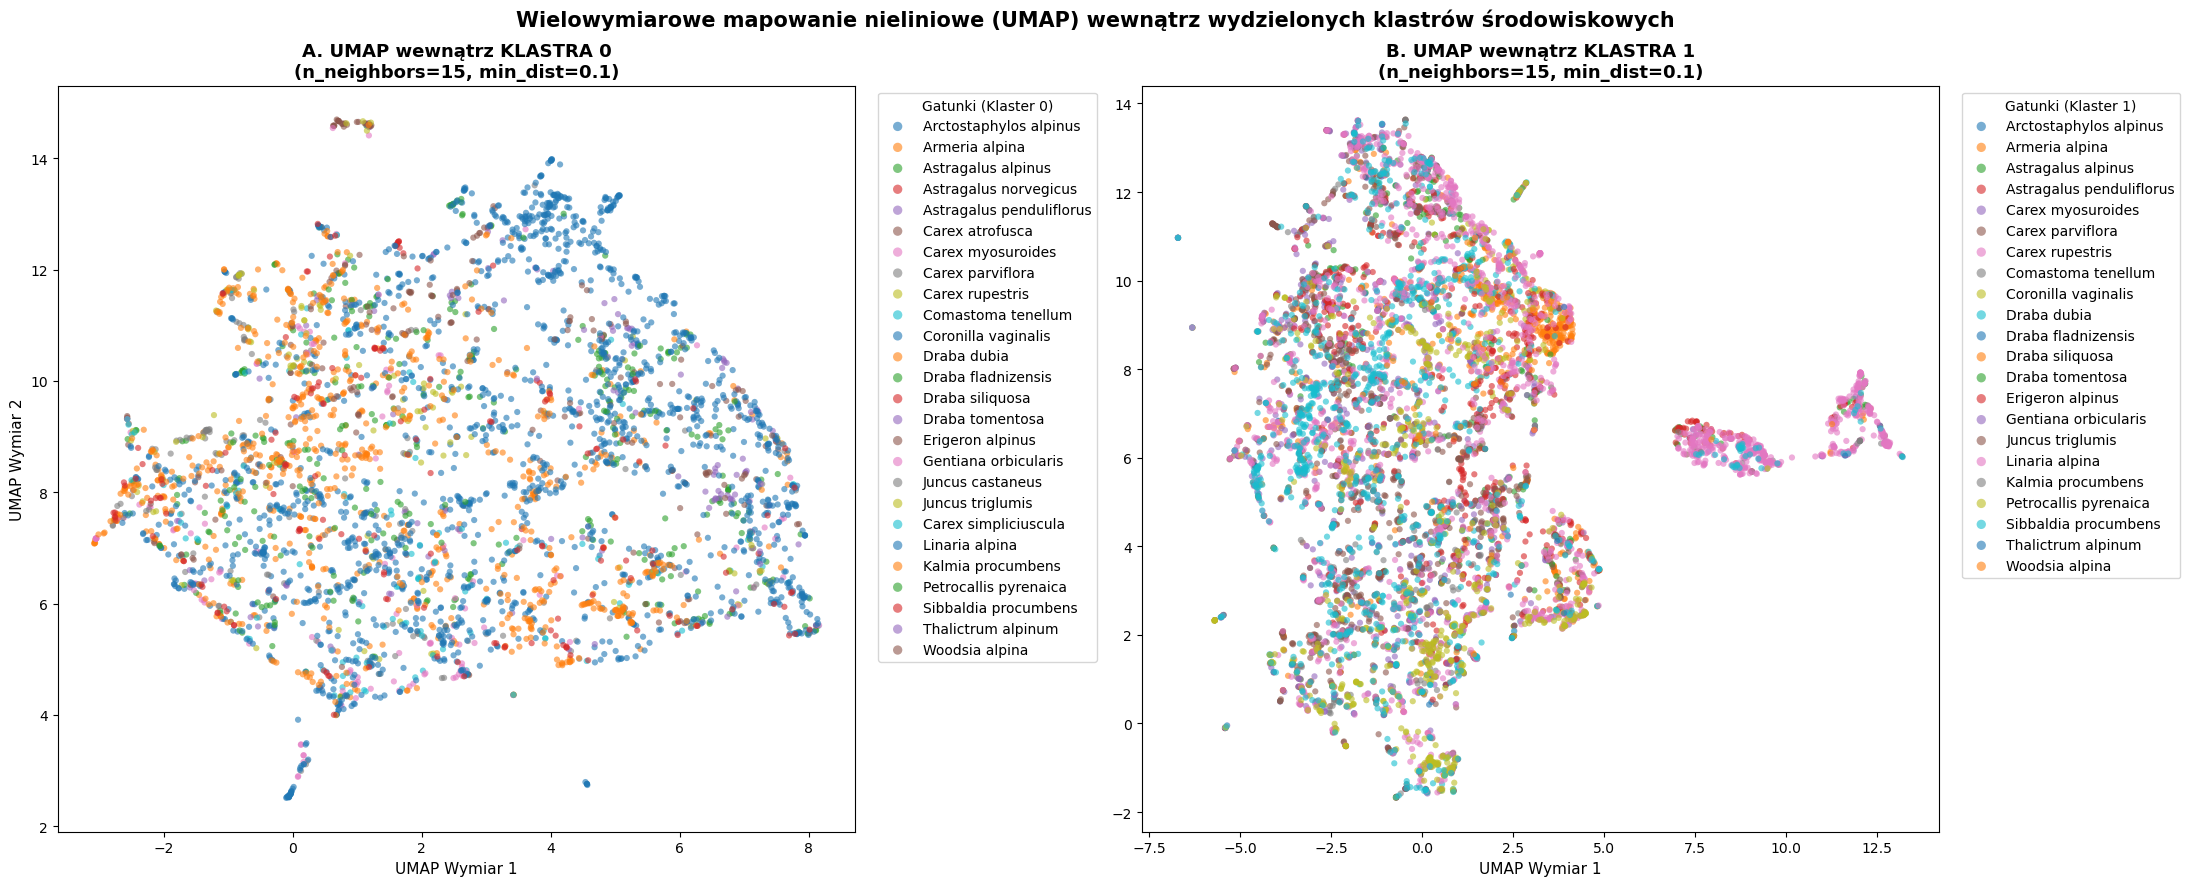

In [86]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import umap

# Upewniamy się, że analizujemy wyłącznie czyste cechy środowiskowe
banned_cols = ["gbifID", "species", "decimalLongitude", "decimalLatitude", "Cluster", "kmeans_cluster"]
features_cols = [col for col in df_clean.columns if col not in banned_cols]

# Wspólne parametry dla obu modeli UMAP (zapewniające stabilność nieliniowego rzutowania)
umap_params = {
    "n_neighbors": 15,
    "min_dist": 0.1,
    "n_components": 2,
    "random_state": 42
}

# =====================================================================
# 1. UMAP WEWNĄTRZ KLASTRA 0
# =====================================================================
df_c0 = df_clean[df_clean["Cluster"] == 0].reset_index(drop=True)
X_c0 = df_c0[features_cols]
y_species_c0 = df_c0["species"]

# Standaryzacja i dopasowanie UMAP dla Klastra 0
scaler_c0 = StandardScaler()
X_scaled_c0 = scaler_c0.fit_transform(X_c0)

reducer_c0 = umap.UMAP(**umap_params)
X_umap_c0 = reducer_c0.fit_transform(X_scaled_c0)

# =====================================================================
# 2. UMAP WEWNĄTRZ KLASTRA 1
# =====================================================================
df_c1 = df_clean[df_clean["Cluster"] == 1].reset_index(drop=True)
X_c1 = df_c1[features_cols]
y_species_c1 = df_c1["species"]

# Standaryzacja i dopasowanie UMAP dla Klastra 1
scaler_c1 = StandardScaler()
X_scaled_c1 = scaler_c1.fit_transform(X_c1)

reducer_c1 = umap.UMAP(**umap_params)
X_umap_c1 = reducer_c1.fit_transform(X_scaled_c1)


# =====================================================================
# 3. WIZUALIZACJA: DWA OSOBNE REJESTRY UMAP (PANEL 1x2)
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))

# --- WYKRES DLA KLASTRA 0 ---
for species_name in y_species_c0.unique():
    mask = y_species_c0 == species_name
    ax1.scatter(
        X_umap_c0[mask, 0],
        X_umap_c0[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none"
    )

ax1.set_title(f"A. UMAP wewnątrz KLASTRA 0\n(n_neighbors={umap_params['n_neighbors']}, min_dist={umap_params['min_dist']})", fontsize=13, fontweight="bold")
ax1.set_xlabel("UMAP Wymiar 1", fontsize=11)
ax1.set_ylabel("UMAP Wymiar 2", fontsize=11)
ax1.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Gatunki (Klaster 0)", markerscale=1.5)

# --- WYKRES DLA KLASTRA 1 ---
for species_name in y_species_c1.unique():
    mask = y_species_c1 == species_name
    ax2.scatter(
        X_umap_c1[mask, 0],
        X_umap_c1[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none"
    )

ax2.set_title(f"B. UMAP wewnątrz KLASTRA 1\n(n_neighbors={umap_params['n_neighbors']}, min_dist={umap_params['min_dist']})", fontsize=13, fontweight="bold")
ax2.set_xlabel("UMAP Wymiar 1", fontsize=11)
ax2.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Gatunki (Klaster 1)", markerscale=1.5)

plt.suptitle("Wielowymiarowe mapowanie nieliniowe (UMAP) wewnątrz wydzielonych klastrów środowiskowych", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()